In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv('../data/raw/student_mental_health.csv')

In [4]:
df.shape

(2000, 17)

In [5]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours',
       'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours',
       'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [7]:
def explore_categorical_values(variable:str,df:pd.DataFrame = df)->str:
  if (df[variable].nunique()>10): return "not categorical"
  return f'Number of categories in {variable}: {df[variable].nunique()}, unique values: {df[variable].unique()}'

In [8]:
print("Manuall Rapport (Observations):")
print('Columns with missvalues:',end=" ")
print('Sleep Hours, GPA, Social_Media_Hours, Financial_Stress, Family_Support, Attendance_Rate, Diet_Quality')
print("student id example:",df.iloc[0,0])
print("Explore Categorical Values:")
print(explore_categorical_values('Gender'))
print(explore_categorical_values('Year_of_Study'))
print(explore_categorical_values('Physical_Activity'))
print(explore_categorical_values('Part_Time_Job'))
print(explore_categorical_values('Diet_Quality'))
print(explore_categorical_values('Previous_Mental_Health_History'))
print(explore_categorical_values('Mental_Health_Risk'))
print('Financial Stress Examples:')
print(df.Financial_Stress.head())

Manuall Rapport (Observations):
Columns with missvalues: Sleep Hours, GPA, Social_Media_Hours, Financial_Stress, Family_Support, Attendance_Rate, Diet_Quality
student id example: STU0001
Explore Categorical Values:
Number of categories in Gender: 3, unique values: <ArrowStringArray>
['Male', 'Female', 'Non-binary']
Length: 3, dtype: str
Number of categories in Year_of_Study: 5, unique values: [3 4 5 1 2]
Number of categories in Physical_Activity: 3, unique values: <ArrowStringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str
Number of categories in Part_Time_Job: 2, unique values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
Number of categories in Diet_Quality: 3, unique values: <ArrowStringArray>
['Poor', 'Average', nan, 'Good']
Length: 4, dtype: str
Number of categories in Previous_Mental_Health_History: 2, unique values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
Number of categories in Mental_Health_Risk: 3, unique values: <ArrowStringArray>
['High', '

In [9]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [10]:
describe = df.describe().T
describe['median'] = df.median(numeric_only=True)
describe

,count,mean,std,min,25%,50%,75%,max,median
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00,21.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00,2.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00,6.70
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30,19.80
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66,2.56
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00,6.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00,8.50
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00,6.10
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90,6.70
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00,85.10


In [11]:
df.describe(include='object')

/tmp/ipykernel_43348/87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


In [12]:
df.isna().sum()[df.isna().sum()>0]

Sleep_Hours           62
GPA                   38
Social_Media_Hours    58
Financial_Stress      91
Family_Support        54
Attendance_Rate       47
Diet_Quality          69
dtype: int64

In [13]:
df.isna().mean()[df.isna().mean()>0]*100

Sleep_Hours           3.10
GPA                   1.90
Social_Media_Hours    2.90
Financial_Stress      4.55
Family_Support        2.70
Attendance_Rate       2.35
Diet_Quality          3.45
dtype: float64

In [14]:
print('duplicated rows:',df.duplicated().sum())
print('duplicated ids:',df['Student_ID'].duplicated().sum())

duplicated rows: 0
duplicated ids: 0


In [15]:
negative_age = df.Age<0
negative_age.sum()
correct_gpa_note = (df.GPA<0) | (df.GPA>5)
correct_gpa_note.sum()
social_media_vs_screen_hours = df.Social_Media_Hours > df.Screen_Time_Hours
social_media_vs_screen_hours.sum()

np.int64(37)

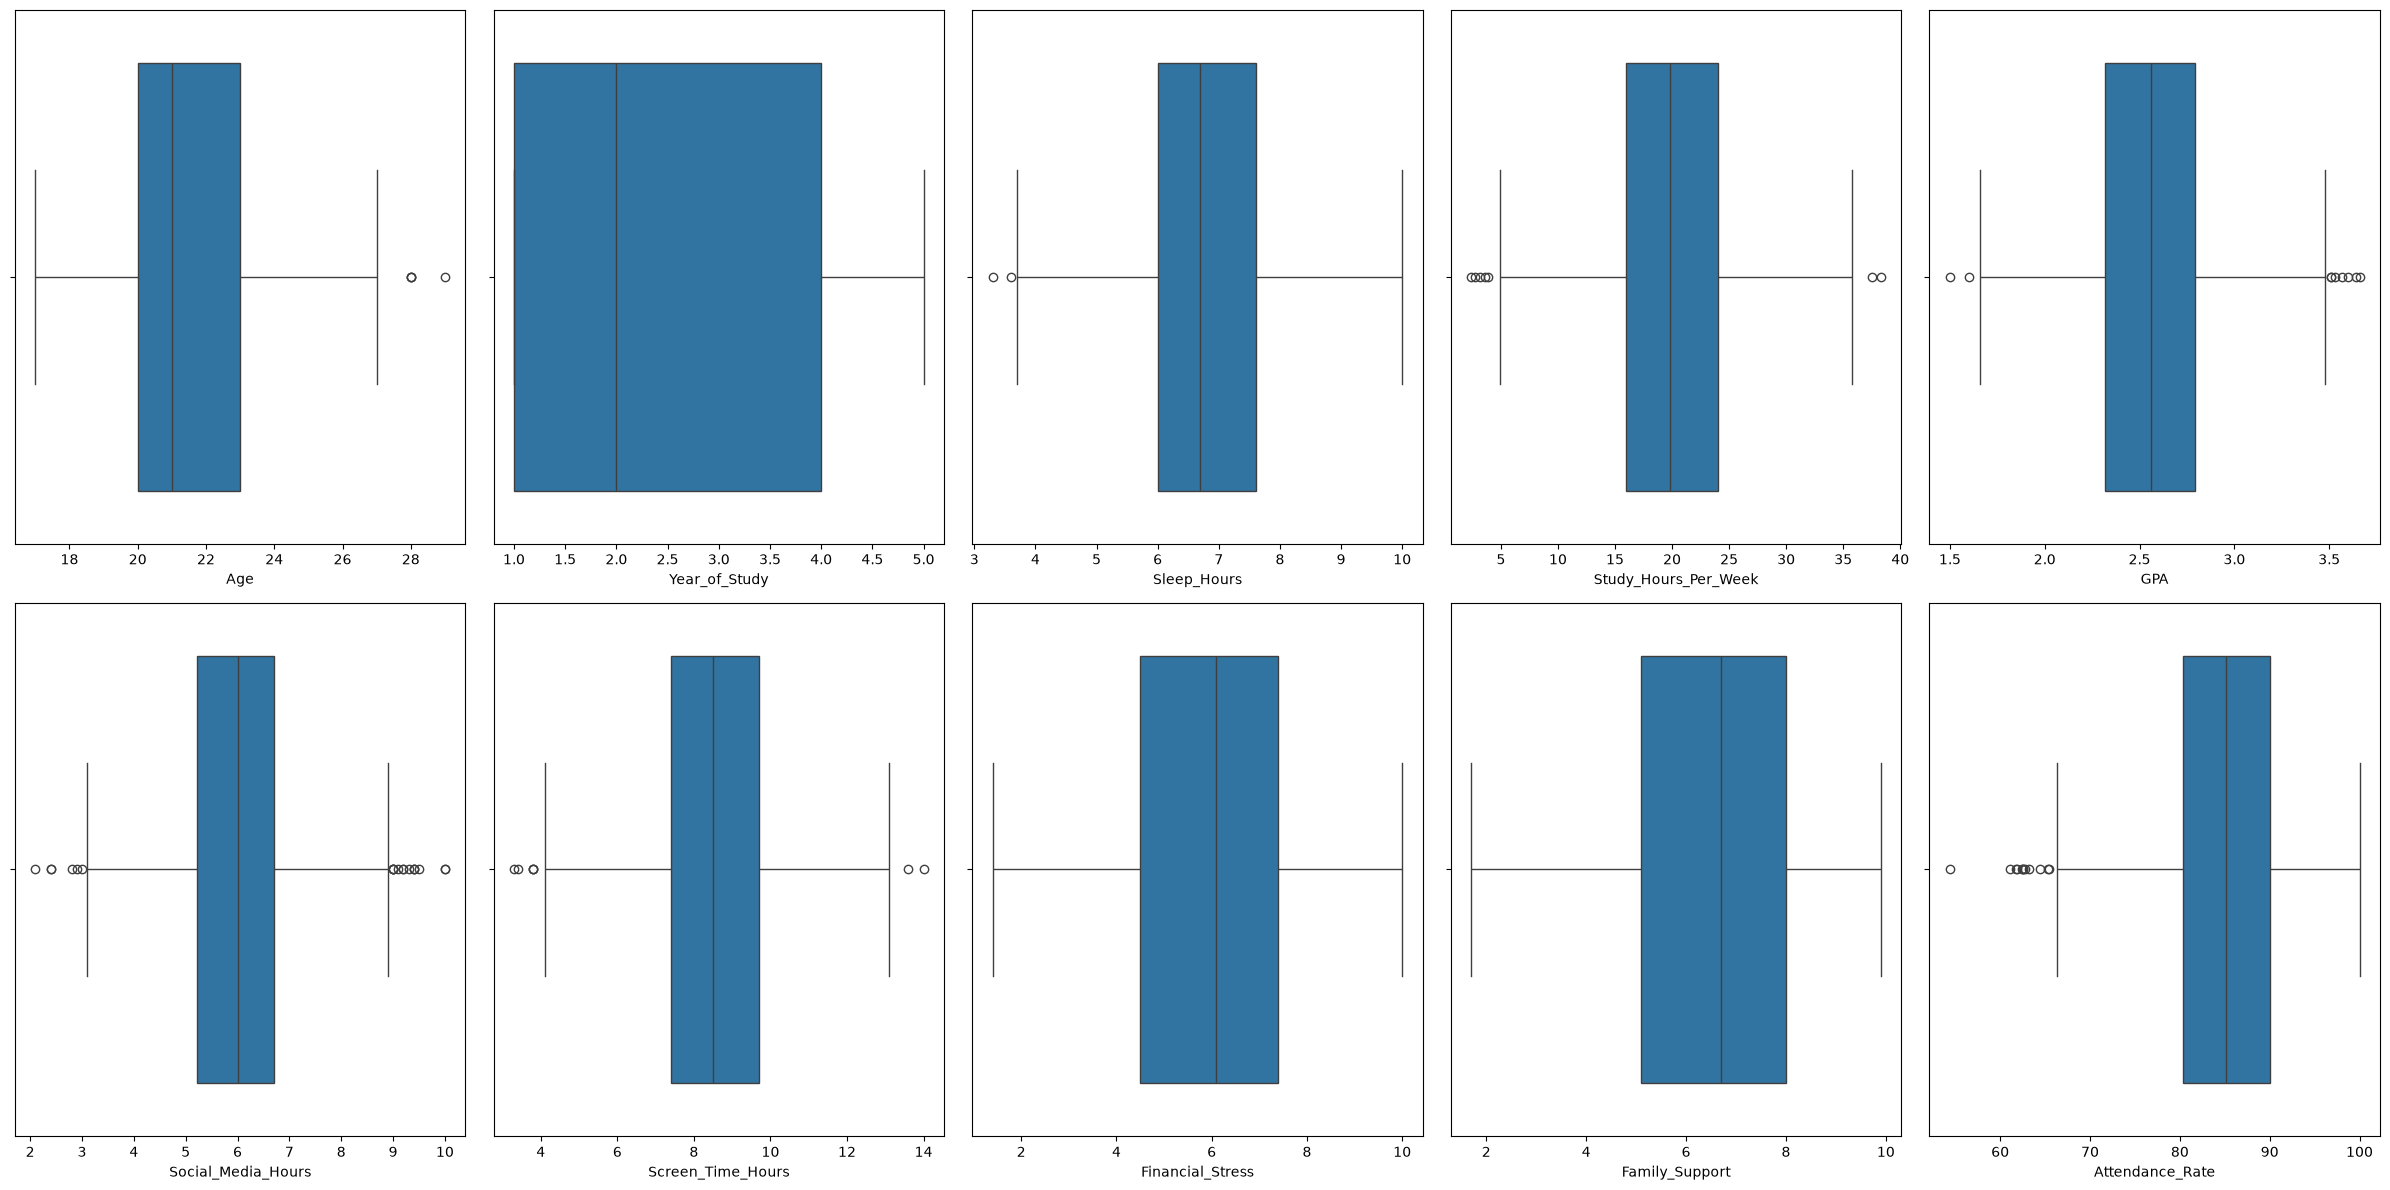

In [16]:
def boxplots(df,nrows,ncols,figure_size):
  fig, axes = plt.subplots(nrows, ncols, figsize=figure_size)
  features = df.select_dtypes(include=[np.number]).columns.to_list()
  for i, feature in enumerate(features):
    row = i // ncols
    col = i % ncols
    sns.boxplot(data=df,x=feature,ax=axes[row,col])
  plt.tight_layout()

boxplots(df,2,5,(24,12))

In [17]:
q1 = df['Attendance_Rate'].quantile(0.25)
q3 = df['Attendance_Rate'].quantile(0.75)
IQR = q3 - q1
lower_threshold = q1 - (1.5 * IQR)
upper_threshold = q3 + (1.5 * IQR)
outliers = df[(df['Attendance_Rate'] < lower_threshold) | (df['Attendance_Rate'] > upper_threshold)]
outliers.sort_values('Attendance_Rate')

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1273,STU1274,20,Male,2,3.9,17.7,2.61,7.8,9.4,Low,7.5,8.8,54.4,No,Average,No,High
36,STU0037,21,Female,3,4.8,24.0,2.25,5.3,6.6,Low,7.7,7.1,61.1,No,Poor,No,High
1407,STU1408,24,Female,3,7.6,21.1,2.23,5.5,7.7,Low,7.8,6.4,61.8,No,Good,No,Medium
1721,STU1722,20,Female,3,5.0,18.4,2.14,7.0,8.9,Moderate,6.6,9.0,61.9,No,Average,No,High
277,STU0278,20,Female,1,6.1,16.2,1.99,5.2,9.1,Low,7.3,5.8,62.4,No,Average,Yes,High
523,STU0524,22,Female,4,6.4,20.8,2.16,5.6,8.5,Moderate,8.4,8.7,62.5,No,Good,Yes,High
906,STU0907,18,Female,3,7.0,17.5,2.11,6.9,9.3,Moderate,8.1,8.3,62.5,Yes,Good,Yes,High
539,STU0540,20,Male,1,6.0,9.4,2.39,5.8,9.4,Moderate,5.4,6.6,62.8,No,NaN,No,Medium
1057,STU1058,24,Male,3,5.0,22.0,2.22,5.4,7.4,Low,8.8,9.6,63.2,No,Good,Yes,High
1645,STU1646,22,Female,5,8.6,29.5,3.00,5.1,7.6,High,3.0,5.7,64.4,No,Average,No,Low


In [18]:
df.Mental_Health_Risk.value_counts()
df.Mental_Health_Risk.value_counts(normalize=True).mul(100)

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64

<Axes: xlabel='Mental_Health_Risk', ylabel='count'>

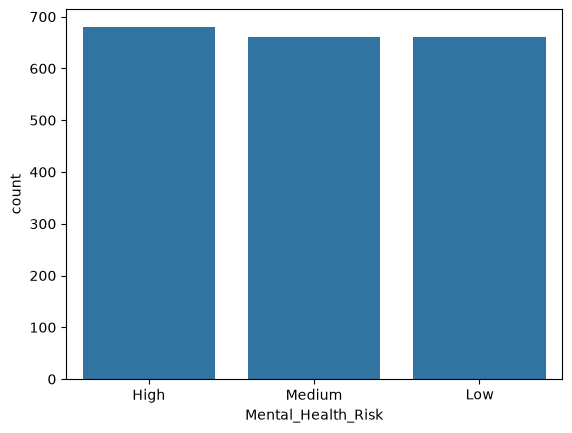

In [19]:
sns.countplot(data=df,x='Mental_Health_Risk')


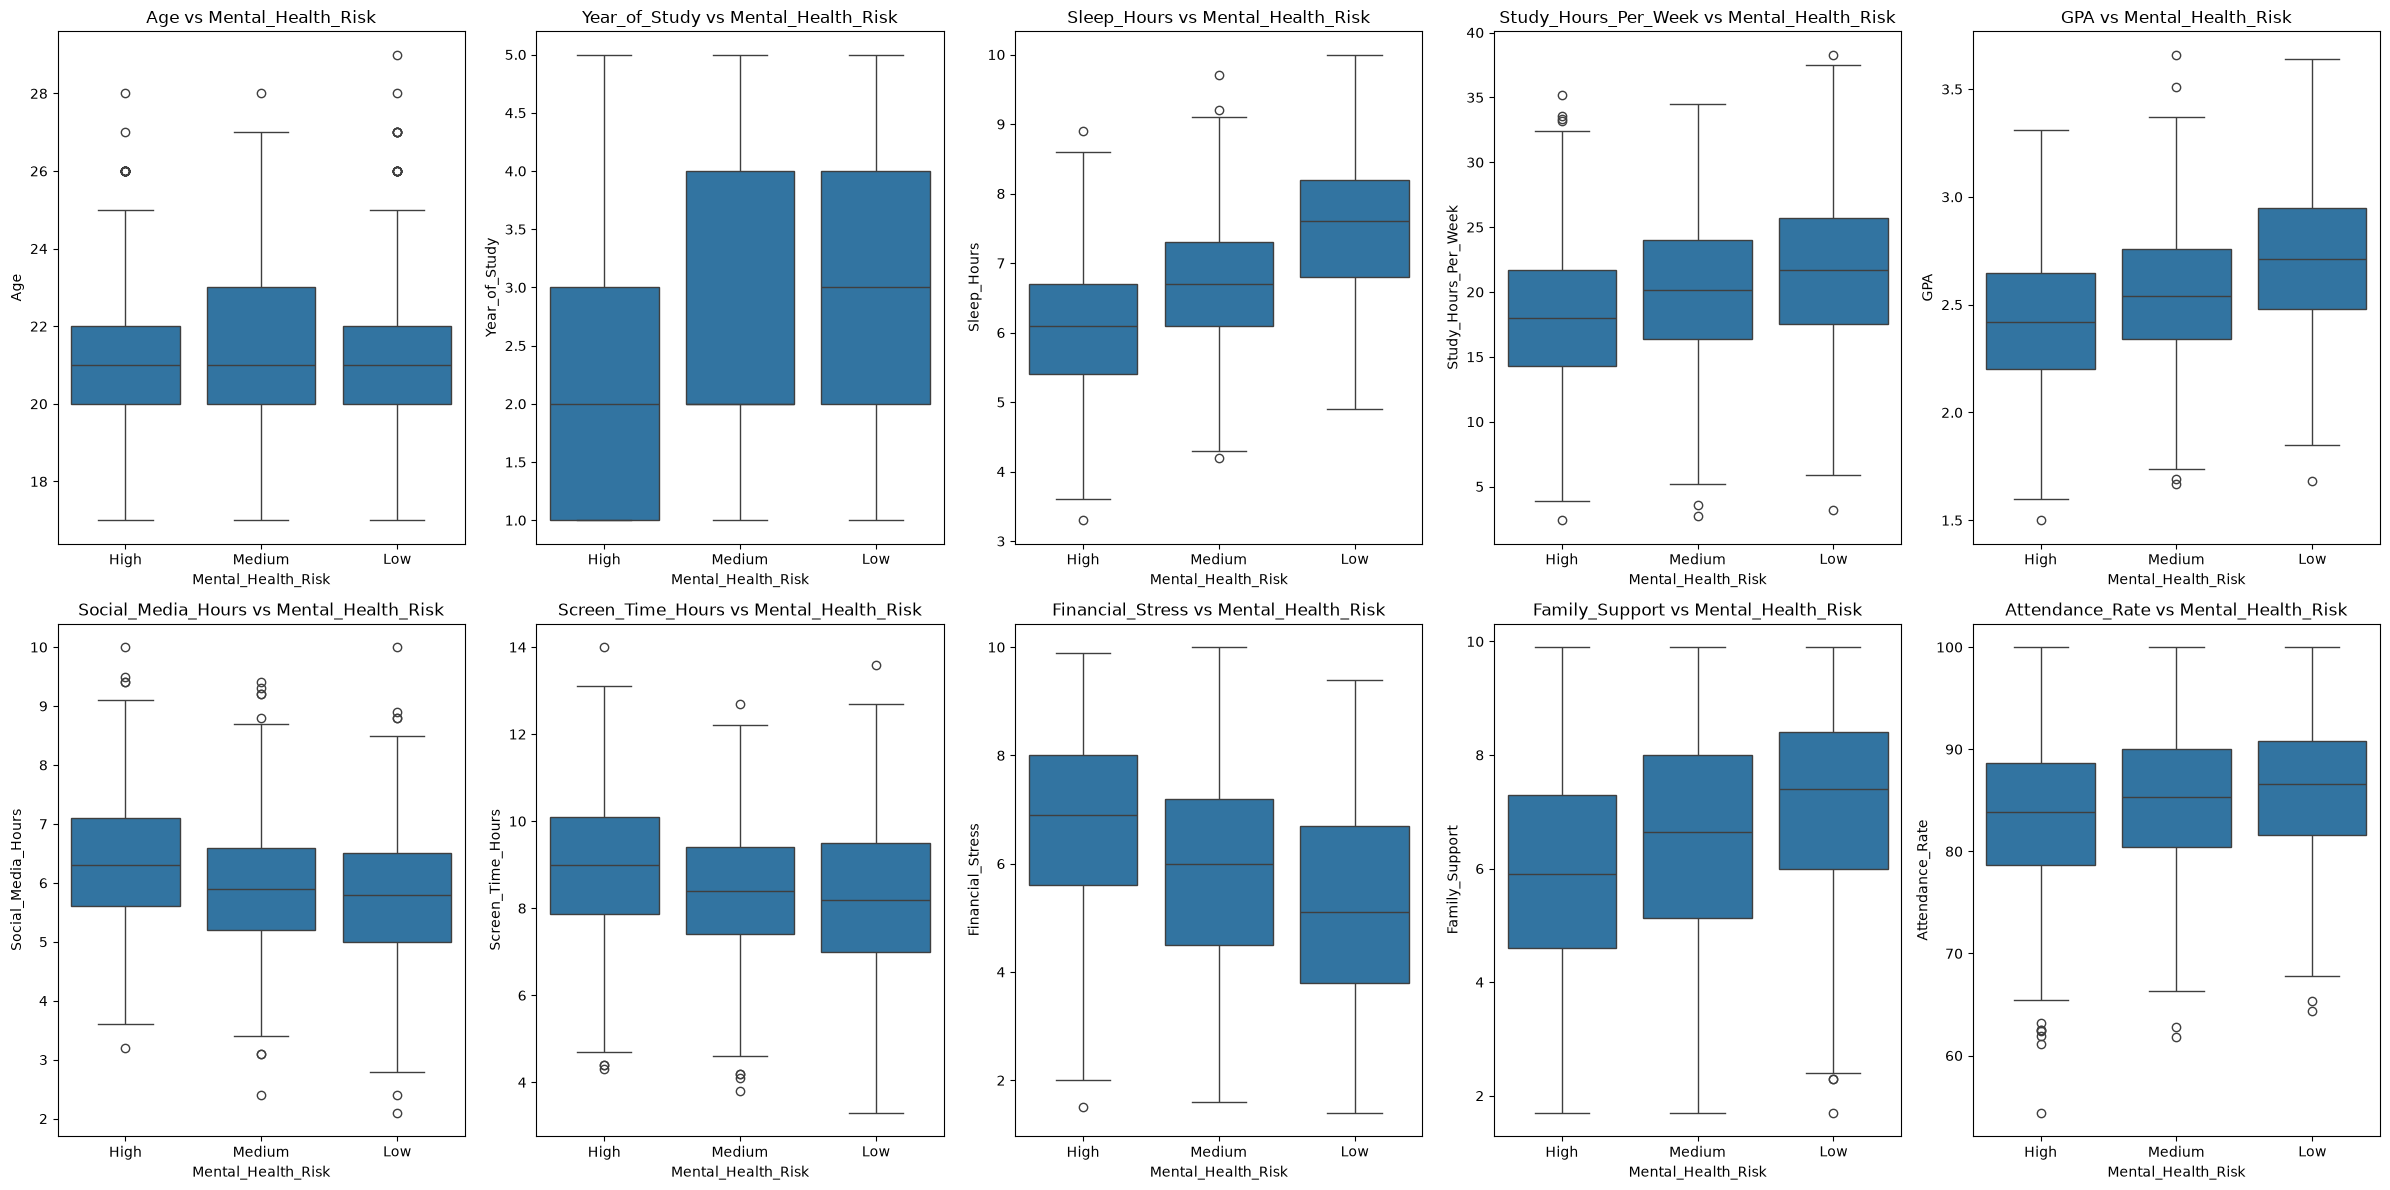

In [20]:
def boxplots_groupedby_target(df,target,nrows,ncols,figure_size):
  fig, axes = plt.subplots(nrows, ncols, figsize=figure_size)
  features = df.select_dtypes(include=[np.number]).columns.to_list()
  for i, feature in enumerate(features):
    row = i // ncols
    col = i % ncols
    sns.boxplot(data=df,x=target,y=feature,ax=axes[row,col])
    axes[row,col].set_title(f'{feature} vs {target}')
  plt.tight_layout()

boxplots_groupedby_target(df,'Mental_Health_Risk',2,5,(24,12))

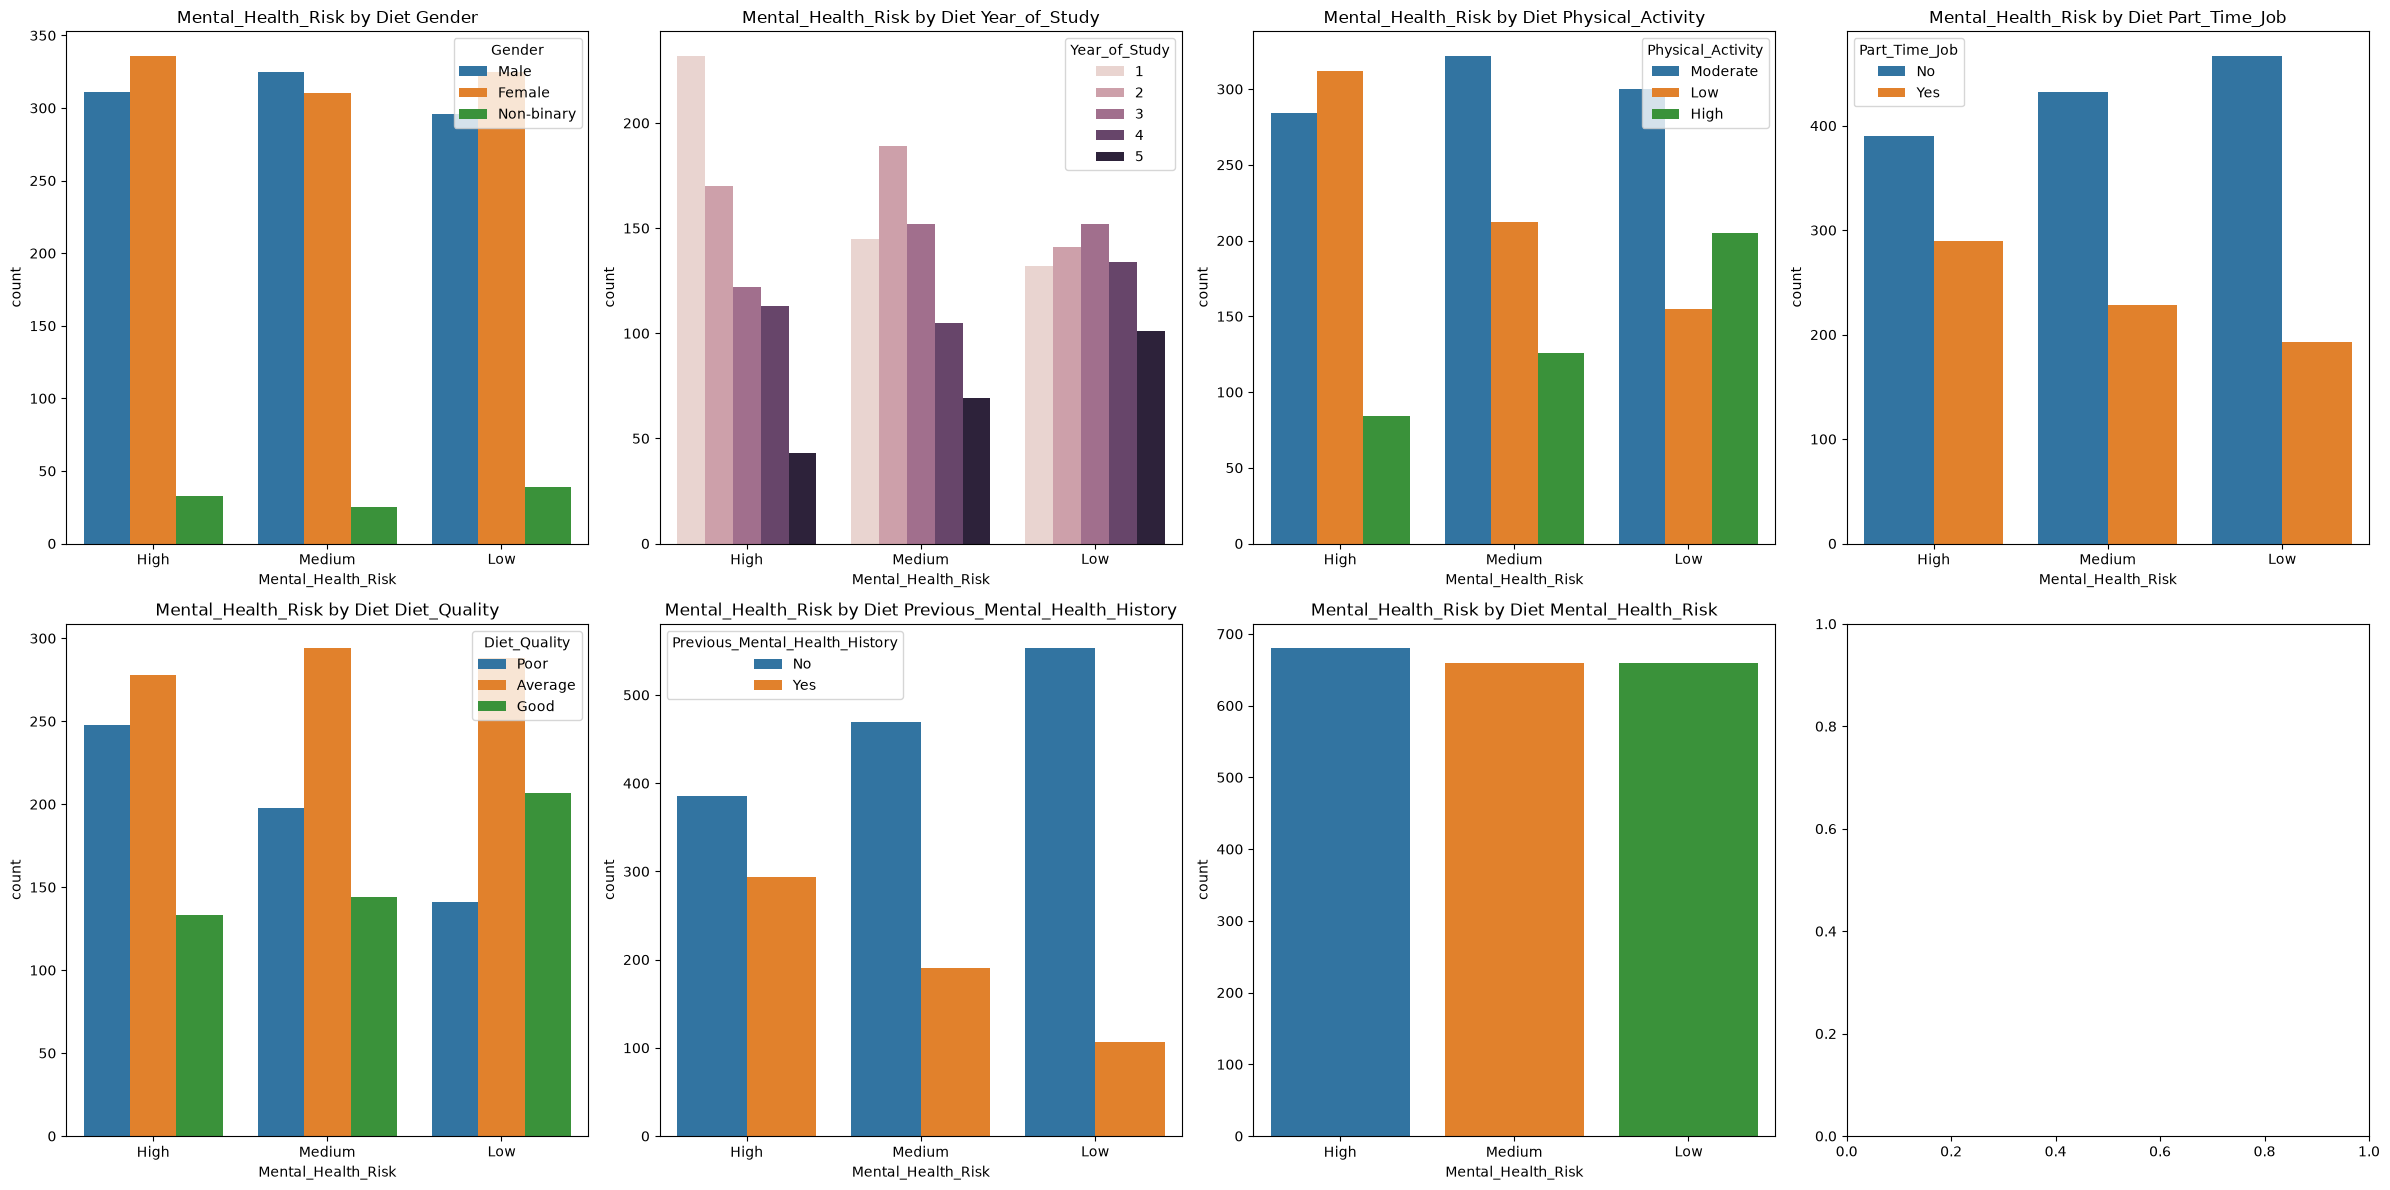

In [21]:
categorical_cols = [
 'Gender',
'Year_of_Study',
'Physical_Activity',
'Part_Time_Job',
'Diet_Quality',
'Previous_Mental_Health_History',
'Mental_Health_Risk'   
]
def countby_target(df,target,categorical_features,nrows,ncols,figure_size):
  fig, axes = plt.subplots(nrows, ncols, figsize=figure_size)
  for i, feature in enumerate(categorical_features):
    row = i // ncols
    col = i % ncols
    sns.countplot(data=df,x=target,hue=feature,ax=axes[row,col])
    axes[row,col].set_title(f"{target} by Diet {feature}")
  plt.tight_layout()

countby_target(df,'Mental_Health_Risk',categorical_cols,2,4,(24,12))

Text(0.5, 1.0, 'Numerical Features Correlation')

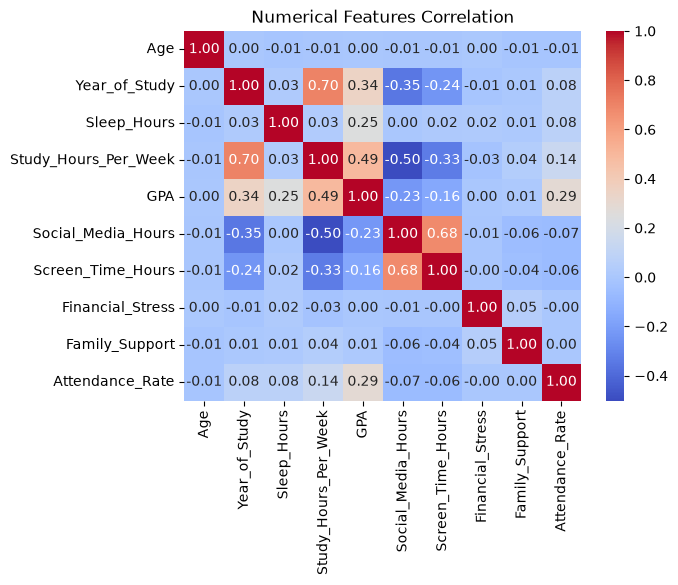

In [22]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr,annot=True,cmap='coolwarm', fmt='.2f')
plt.title('Numerical Features Correlation')